# Question 2 — ¿Pueden las señales de precio conseguir lo que consigue el despacho central?

**Guía de estudio (Alejandro, grupo 14).** Este notebook va en paralelo a la [Sección Q2 del informe](../../Report_LaTeX/sources/2_.tex) y a la parte C del [Formative assessment 1](../../Report_LaTeX/formative_assessment_1/Group14_formative_assessment_1.tex).
La idea es que entiendas *por qué* cada ecuación está ahí y que puedas defenderla en el examen oral.
Todo lo que se ejecuta aquí usa el código real del repositorio (`src/models.py` de Erik para $\mathcal R,\mathcal I,\mathcal C$ y `src/pricing.py` para $\mathcal{DP}$).

**Cómo leerlo.** Cada sección empieza con la idea en una frase, sigue con la teoría (con referencias a los documentos de tu carpeta) y termina con un experimento pequeño que la comprueba numéricamente.

| # | Sección | Qué aprendes |
|---|---|---|
| 0 | Mapa de referencias | Dónde está cada concepto en tus libros y lecture notes |
| 1 | El problema en 5 minutos | DSO, contrato, comunidad, qué pide Q2 |
| 2 | Repaso de Q1 (lo que hizo Erik) | $\mathcal R,\mathcal I,\mathcal C$, precio interno $\lambda_t$, renta de congestión |
| 3 | Juegos de Stackelberg y problemas bilevel | líder/seguidor, región inducible, optimista vs pesimista |
| 4 | El problema del miembro a precios $x_t$ | best response, por qué es un *conjunto* |
| 5 | Condiciones KKT del miembro | cada dual y su significado |
| 6 | Del bilevel al MILP | KKT → complementariedad → big-M/SOS1; dualidad fuerte para los pagos |
| 7 | Validación: $\mathcal{DP}^{cap}=\mathcal C$ | el teorema de descentralización en acción |
| 8 | Budget balance | quién cobra la renta y cómo devolverla |
| 9 | Individual rationality | quién bloquea y cuánto cuesta |
| 10 | Indiferencia | qué arriesga el manager por ser optimista |
| 11 | Qué falta para la Round 2 | estudio en tres pasos y sensibilidad |

## 0. Mapa de referencias (todo está en tu carpeta `Assignment_2/`)

| Concepto | Dónde leerlo |
|---|---|
| Enunciado de Q2 (qué hay que entregar) | [Instrucciones del Assignment 2](../../Assignment_2_Learn/Assignment%202%20-%20Instructions.html), sección *Question 2* |
| Equilibrio vs jerarquía, Stackelberg | [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §2–§3; [Slides semana 7](../../Slides/%5BLecture%20slides%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.pdf) |
| Conjuntos del bilevel: $\mathcal F^F(x)$, $\mathcal S(x)$, región inducible $\mathcal{IR}$, optimista/pesimista | [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §4 |
| El líder no conoce al seguidor (enlace con Q3) | [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §5 |
| Bilevel → MPEC; cuándo se puede sustituir el seguidor por sus KKT | [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §7–§8; [Gabriel et al., *Complementarity Modeling in Energy Markets*](../../Books/complementarity%20modelling%20in%20energy%20markets.pdf), §6.2.5 (p. 235, PDF p. 256) y §6.3.1 *MPPDC* (p. 241, PDF p. 262) |
| Linealizar complementariedad: big-M (Fortuny-Amat) y SOS1; cómo elegir M | [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §9; [Gabriel et al., *Complementarity Modeling in Energy Markets*](../../Books/complementarity%20modelling%20in%20energy%20markets.pdf), §6.4.1–6.4.2 (p. 250–251, PDF p. 271–272); [Sioshansi & Conejo, *Optimization in Engineering*](../../Books/optimization%20in%20engineering.pdf), §3.3 |
| Dualidad fuerte para quitar el producto precio × cantidad | [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §9 (*Linearizing the objective with strong duality*); [Gabriel et al., *Complementarity Modeling in Energy Markets*](../../Books/complementarity%20modelling%20in%20energy%20markets.pdf), §6.3.1 |
| KKT, holgura complementaria | [Lecture notes – Duality and optimality conditions](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Duality%20and%20Optimality%20Conditions%20The%20Value%20of%20a%20Constraint.html); [Boyd & Vandenberghe, *Convex Optimization*](../../Books/Convex%20optimization.pdf), §5.5.2–5.5.3 (p. 242–243, PDF p. 256–257); [Gabriel et al., *Complementarity Modeling in Energy Markets*](../../Books/complementarity%20modelling%20in%20energy%20markets.pdf), §2.3 (p. 39, PDF p. 64) |
| Dual de un LP | [Boyd & Vandenberghe, *Convex Optimization*](../../Books/Convex%20optimization.pdf), §5.2 (p. 223, PDF p. 237); [Sioshansi & Conejo, *Optimization in Engineering*](../../Books/optimization%20in%20engineering.pdf), §2.7 |
| MPEC en general | [Gabriel et al., *Complementarity Modeling in Energy Markets*](../../Books/complementarity%20modelling%20in%20energy%20markets.pdf), §2.8 (p. 53, PDF p. 78); [Conejo et al., *Investment in Electricity Generation and Transmission*](../../Books/investment%20in%20electricity%20generation%20and%20transmission.pdf), Apéndice C (PDF p. 352) |
| Precio marginal, *budget balance*, *revenue adequacy*, equilibrio competitivo (*invisible hand*) | [Lecture notes – Pricing in electricity markets](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Pricing%20in%20Electricity%20Markets.html), §4–§5 |
| Valor de la energía almacenada (duales de la batería) | [Lecture notes – The value of stored energy](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Multi-period%20Optimization%20The%20Value%20of%20Stored%20Energy.html) |
| Modelos de Q1 y su notación | [Sección Q1 del informe (Erik)](../../Report_LaTeX/sources/1_.tex) |
| Referencia del mecanismo | Crowley, Kazempour, Mitridati, *Applied Energy* 382 (2025) 125154 — ref. [1] del enunciado (no está en la carpeta; es open access) |

## 1. El problema en 5 minutos

- Un **DSO** tiene congestión en un feeder que alimenta a 16 prosumidores. En vez de reforzar la red ofrece un **contrato de limitación de capacidad**: un cap horario $\overline P^{DSO}_t$ en la importación, una penalización $\alpha^{DSO}$ por kWh por encima del cap y un descuento $\beta^{DSO}$ en las tarifas.
- **Q1** (Erik) comparó tres opciones: no firmar ($\mathcal R$), firmar cada uno ($\mathcal I$), firmar como comunidad con despacho central ($\mathcal C$).
- **Q2** (tú): el manager de la comunidad **ya no controla** las cargas. Sólo puede **publicar un precio interno por hora $x_t$** (el mismo para todos). Cada miembro responde optimizando por su cuenta. Preguntas:
  1. ¿Cuánto del valor de $\mathcal C$ se recupera con un único precio por hora? ¿Qué propiedad de los miembros lo explica?
  2. ¿Puede ese mismo precio *además* repartir los costes de forma que nadie pierda (budget balance + individual rationality)?
  3. ¿Cuánto cuesta ese requisito a la comunidad? Si no se puede, ¿quién bloquea?
- Entregables del modelo (enunciado): el problema $\mathcal{DP}$ (manager + miembros), el *solution concept*, la reformulación a MILP, variantes $\mathcal{DP}^x$ con BB/IR y una forma de tratar la infactibilidad, el estudio en **tres pasos** (cap → +BB → +IR), una sensibilidad a los términos del contrato y una discusión de la **indiferencia**.

Community            : base (EC_base), day d1 - Monday (Assignment 1 day)
Members              : 16  (L1 x1, L1+BAT x1, L1+PV x1, L1+PV+BAT x1, L2 x1, L2+BAT x1, L2+PV x1, L2+PV+BAT x1, L3 x1, L3+BAT x1, L3+PV x1, L3+PV+BAT x1, L4 x1, L4+BAT x1, L4+PV x1, L4+PV+BAT x1)
Slope classes        : L1 x4, L2 x4, L3 x4, L4 x4
Connected load / PV  : 48 kW / 24 kW (8 systems); batteries 8
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Tariffs imp/exp      : 0.50 / 0.40 DKK/kWh, discount beta = 0.75
Cap                  : 9.39 - 9.39 kW (daily energy 225.4 kWh = 1.3 x import without contract), penalty 10.0 DKK/kWh
Individual caps (I)  : shares (energy_net) C1 0.104, C1_PV 0.020, C1_B 0.106, C1_PVB 0.020, ...


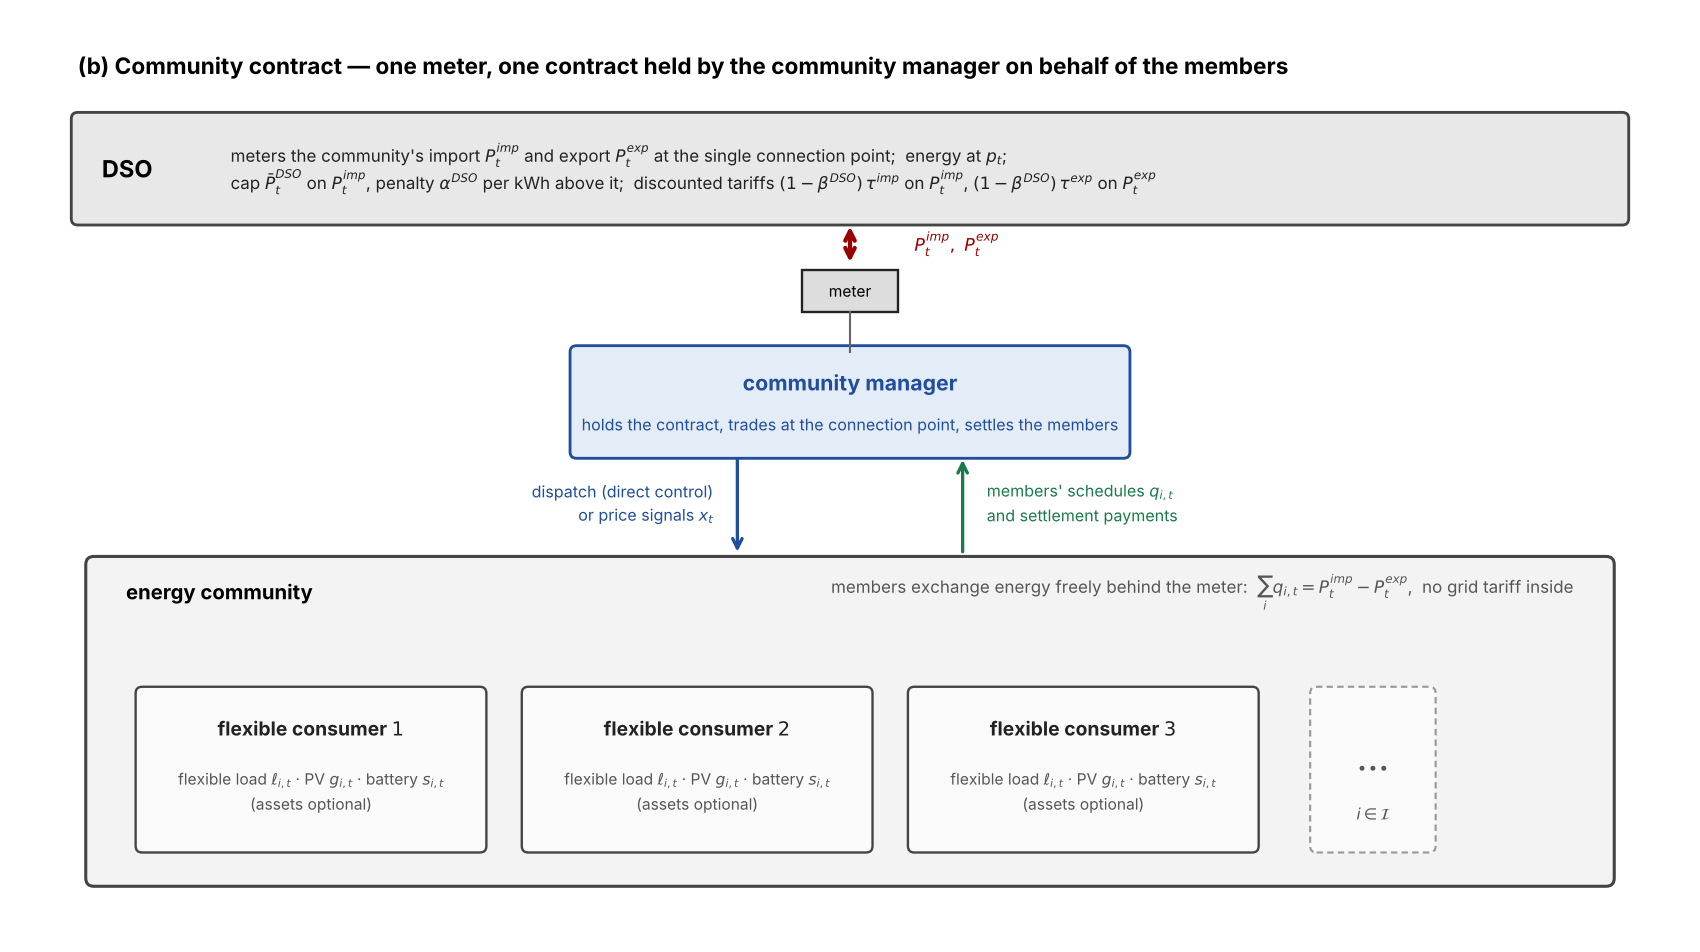

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src.data_loader import load_community
from src.models import CommunityModel
from src.pricing import PricingModel, best_response, response_range, pessimistic_import

com = load_community("base")          # 16 miembros, día d1
print(com.summary())
display(Image(filename=str(ROOT / "data" / "community_base_case.png"), width=650))

## 2. Repaso de Q1: el precio interno $\lambda_t$ y la renta de congestión

En $\mathcal C$ el manager resuelve un único LP (ver [Sección Q1 del informe (Erik)](../../Report_LaTeX/sources/1_.tex), ec. `eq:C`):

$$\min\ \underbrace{\sum_t \big(\tilde p^{imp}_t P^{imp}_t-\tilde p^{exp}_t P^{exp}_t+\alpha P^{exc}_t\big)}_{D:\ \text{factura del DSO}}+\sum_i K_i
\quad\text{s.a.}\quad \sum_i q_{i,t}=P^{imp}_t-P^{exp}_t\ (:\lambda_t),\quad P^{exc}_t\ge P^{imp}_t-\overline P_t\ (:\gamma_t).$$

- $\lambda_t$ (dual del balance interno) = coste para la comunidad de 1 kWh más consumido en la hora $t$. Por las KKT: $\lambda_t=\tilde p^{exp}_t$ si exporta, $\tilde p^{imp}_t$ si importa bajo el cap, $\tilde p^{imp}_t+\gamma_t$ en el cap, entre $\tilde p^{exp}_t$ y $\tilde p^{imp}_t$ si no intercambia. Es el mismo argumento de la "escalera de precios" del Assignment 1 y de [Lecture notes – Pricing in electricity markets](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Pricing%20in%20Electricity%20Markets.html), §2.
- **Settlement dual**: cada miembro paga $\Pi_i=\sum_t\lambda_t q_{i,t}$. Sumando por régimen: $B=\sum_i\Pi_i-D=\sum_t\gamma_t\overline P_t\ge 0$ = **renta de congestión**. El manager *sobre-recauda*: es exactamente lo que Q2 quiere arreglar.

J^R = 398.24  J^I = 480.67  J^C = 372.16 DKK
Renta de congestión B = 163.77 DKK  vs  ganancia de la comunidad V^C = 26.08 DKK
Precios internos distintos de C: [np.float64(1.41), np.float64(1.525), np.float64(1.625), np.float64(1.7), np.float64(1.895), np.float64(1.91), np.float64(2.0), np.float64(2.1), np.float64(2.4), np.float64(2.41), np.float64(3.41), np.float64(5.41)]


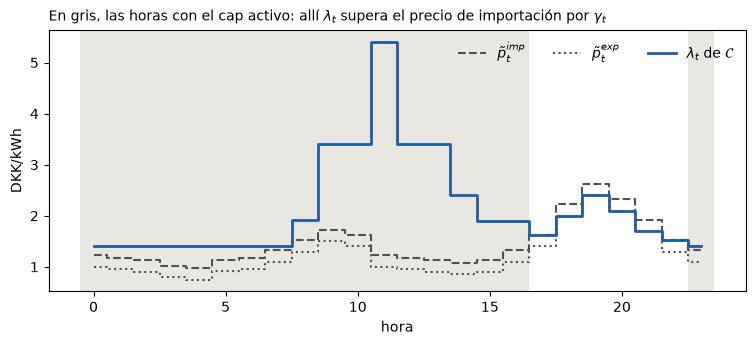

In [2]:
R, I, C = (CommunityModel(com, m).solve() for m in ("R", "I", "C"))
mC = CommunityModel(com, "C"); mC.solve()
print(f"J^R = {R.cost['total']:.2f}  J^I = {I.cost['total']:.2f}  J^C = {C.cost['total']:.2f} DKK")
print(f"Renta de congestión B = {C.surplus:.2f} DKK  vs  ganancia de la comunidad V^C = {R.cost['total']-C.cost['total']:.2f} DKK")
print("Precios internos distintos de C:", sorted(set(np.round(C.price, 3))))

hours = np.arange(24)
at_cap = C.feeder_import >= C.cap - 1e-6
fig, ax = plt.subplots(figsize=(9, 3.4))
for t in hours[at_cap]:
    ax.axvspan(t - 0.5, t + 0.5, color="#e9e7e2", lw=0)
ax.step(hours, mC.p_imp, where="mid", color="#52514e", ls="--", label=r"$\tilde p^{imp}_t$")
ax.step(hours, mC.p_exp, where="mid", color="#52514e", ls=":", label=r"$\tilde p^{exp}_t$")
ax.step(hours, C.price, where="mid", color="#1c5cab", lw=2, label=r"$\lambda_t$ de $\mathcal{C}$")
ax.set_xlabel("hora"); ax.set_ylabel("DKK/kWh"); ax.legend(frameon=False, ncol=3)
ax.set_title("En gris, las horas con el cap activo: allí $\\lambda_t$ supera el precio de importación por $\\gamma_t$", loc="left", fontsize=10)
plt.show()

**Lee la figura.** Fuera del cap, $\lambda_t$ está pegado al precio de importación o de exportación descontado. En el cap se separa hacia arriba y lo fija el **miembro marginal**:
- Si es una carga, vale el precio de la noche (1.41) más $2c^L$ de su clase: 1.91 (L1), 2.41 (L2), 3.41 (L3), 5.41 (L4). Una carga mueve 1 kWh de la hora $t$ a la $s$ sólo si $x_t-x_s>2c^L$: pierde $c^L$ al bajar en $t$ y otro $c^L$ al subir en $s$.
- Si es una batería, como en las horas 15–16, el precio es 1.895. Allí sólo los dueños de batería son indiferentes (sección 10).

Es un **merit order de flexibilidad**: cuanto más aprieta el cap en una hora, más rígida es la clase que hay que mover y más sube el precio. En la hora 11 tienen que moverse hasta las L4 (el enunciado lo pide como *expected insight*).

## 3. Stackelberg y problemas bilevel (teoría)

> **Idea en una frase**: el manager decide primero ($x$) y **anticipa** cómo reaccionarán los miembros. Optimiza sobre las parejas (precio, respuesta óptima a ese precio), no sobre todos los despachos factibles.

Notación de [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §4:
- Líder: $x$ (precios). Seguidores: $y_i$ (horarios de cada miembro).
- $\mathcal F^F(x)$: conjunto factible del seguidor dado $x$. **Aquí no depende de $x$**: $\mathcal X_i$ es el mismo de Q1. El precio sólo entra en el *objetivo* del miembro. Es el caso *"strategic in price"* del §7/§9 de las notas: el líder inclina el objetivo del seguidor.
- $\mathcal S(x)=\arg\min$ del seguidor; **región inducible** $\mathcal{IR}=\{(x,y):y\in\mathcal S(x)\}$. Es no convexa incluso si todo es lineal (§4, *Three properties*).
- Si $\mathcal S(x)$ tiene más de un punto hay que decidir quién elige: **optimista** (el solver elige a favor del líder, que es lo que devuelve un MPEC) o **pesimista** ($\min_x\max_{y\in\mathcal S(x)}$).

**¿Por qué no es una "simple" optimización?** Porque $\mathcal C$ optimiza sobre *todo* el conjunto factible; $\mathcal{DP}$ sólo sobre $\mathcal{IR}\subseteq$ ese conjunto. Por tanto **siempre** $J^{\mathcal{DP}}\ge J^{\mathcal C}$. La pregunta 1 de Q2 es si la desigualdad es estricta.

📖 Profundiza: [Gabriel et al., *Complementarity Modeling in Energy Markets*](../../Books/complementarity%20modelling%20in%20energy%20markets.pdf), §6.1–6.2 (p. 221–235, PDF p. 242–256), sobre todo §6.2.5: *"constraining problems need to be convex"*.

## 4. El problema del miembro a precios $x_t$ (el seguidor)

$$\mathcal F_i(x):\quad\min_{y_i\in\mathcal X_i}\ \sum_t x_t\,q_{i,t}+K_i,\qquad q_{i,t}=\ell_{i,t}+p^{ch}_{i,t}-p^{dis}_{i,t}-q^{PV}_{i,t}\ \text{(libre de signo)}.$$

**Qué cambia respecto a $\mathcal R$:**
1. Desaparecen $q^{imp},q^{exp}$ y el balance `eq:R_bal`: el miembro no tiene contador propio frente al DSO.
2. Dos precios ($p^{imp}_t>p^{exp}_t$) → **un solo precio** $x_t$ para comprar y vender.
3. Tarifas y penalización desaparecen del problema del miembro: las paga el manager en el punto de conexión.

**Consecuencias de comprar y vender al mismo precio** (el enunciado lo pide explícitamente):
- **PV**: un kWh vale $x_t$ lo autoconsuma, lo venda a un vecino o se exporte. No hay prima por autoconsumo. Produce si $x_t>c^{PV}=1.41$, recorta si $x_t<1.41$ y es indiferente si $x_t=1.41$.
- **Batería**: sólo arbitra diferencias de precio. Mueve energía de $t$ a $s$ si $\eta^{ch}\eta^{dis}x_s>x_t$. Con $x_t\ge0$ nunca gana cargando y descargando a la vez.
- **Presupuesto del manager**: por hora es $(x_t-\tilde p^{imp}_t)P^{imp}_t-(x_t-\tilde p^{exp}_t)P^{exp}_t-\alpha P^{exc}_t$. Sólo se equilibra si $x_t$ coincide con el precio del contador en la dirección del flujo.

**Por qué la respuesta es un *conjunto*.** Con desutilidad lineal $c^L|\ell-\hat\ell|$, el miembro compara $x_t$ con su "valor interno" del kWh diario $\mu^E_i$ (el multiplicador de $E^{\min}$). Mantiene la referencia si $|x_t-\mu^E_i|<c^L_i$, va a un límite si la diferencia es mayor y **es indiferente si es exactamente $c^L_i$**. Es la escalera de tres regímenes del Assignment 1, ahora con un único precio.

Experimento: barremos el precio de la hora 11 para el miembro C1 (L1, sin activos), manteniendo el resto de precios en $\lambda^{\mathcal C}$.

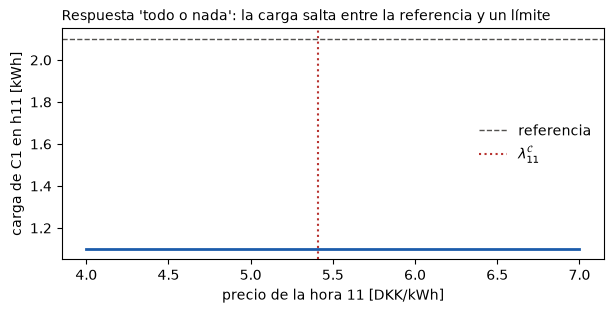

Horas en las que C1 es indiferente a x = lambda^C: [0, 1, 2, 3, 4, 5, 6, 7, 8, 23]


In [3]:
m = com.member("C1")
grid = np.round(np.arange(4.0, 7.01, 0.05), 3)
load11 = []
for p11 in grid:
    x = C.price.copy(); x[11] = p11
    load11.append(best_response(m, x)["schedule"]["l"][11])
fig, ax = plt.subplots(figsize=(7, 3))
ax.step(grid, load11, where="mid", color="#1c5cab", lw=2)
ax.axhline(m.reference_load[11], color="#52514e", ls="--", lw=1, label="referencia")
ax.axvline(C.price[11], color="#b8322f", ls=":", label=r"$\lambda_{11}^{\mathcal{C}}$")
ax.set_xlabel("precio de la hora 11 [DKK/kWh]"); ax.set_ylabel("carga de C1 en h11 [kWh]"); ax.legend(frameon=False)
ax.set_title("Respuesta 'todo o nada': la carga salta entre la referencia y un límite", loc="left", fontsize=10)
plt.show()
lo, hi = response_range(m, C.price)
print("Horas en las que C1 es indiferente a x = lambda^C:", [t for t in range(24) if hi[t] - lo[t] > 1e-5])

## 5. Condiciones KKT del miembro

El LP del miembro es convexo con restricciones lineales, así que las KKT son **necesarias y suficientes** ([Lecture notes – Duality and optimality conditions](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Duality%20and%20Optimality%20Conditions%20The%20Value%20of%20a%20Constraint.html); [Boyd & Vandenberghe, *Convex Optimization*](../../Books/Convex%20optimization.pdf) §5.5.3). Esto es lo que permite sustituirlo por sus KKT sin cambiar $\mathcal S(x)$ ([Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §8).

Duales (todos definidos en `add_member_kkt` de `src/pricing.py`):

| Restricción | Dual | Signo | Significado |
|---|---|---|---|
| $\ell_t-\hat\ell_t=d^+_t-d^-_t$ | $\nu_t$ | libre, $|\nu_t|\le c^L$ | valor marginal de desviarse en $t$ |
| $\sum_t\ell_t\ge E^{\min}$ | $\mu^E$ | $\ge0$ | valor interno de un kWh de necesidad diaria |
| $\ell^{lo}_t\le\ell_t\le\ell^{up}_t$ | $\underline\mu^L_t,\overline\mu^L_t$ | $\ge0$ | límites horarios ($\pm\Delta$) |
| $0\le q^{PV}_t\le G_t$ | $\underline\mu^{PV}_t,\overline\mu^{PV}_t$ | $\ge0$ | renta de la PV $=(x_t-c^{PV})^+$ |
| dinámica SoC | $\psi_t$ | libre | $-\psi_t$ = valor de la energía almacenada ([Lecture notes – The value of stored energy](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Multi-period%20Optimization%20The%20Value%20of%20Stored%20Energy.html)) |
| límites de batería, $e_{23}\ge e^{init}$ | $\underline\mu,\overline\mu,\mu^{end}$ | $\ge0$ | |

Estacionariedad (derivada del Lagrangiano, con $q$ sustituido):

$$\ell_t:\ x_t-\nu_t-\mu^E-\underline\mu^L_t+\overline\mu^L_t=0;\quad d^\pm_t:\ 0\le d^\pm_t\perp c^L\pm\nu_t\ge0;\quad q^{PV}_t:\ -x_t+c^{PV}-\underline\mu^{PV}_t+\overline\mu^{PV}_t=0$$
$$p^{ch}_t:\ x_t+\eta^{ch}\psi_t-\underline\mu^{ch}_t+\overline\mu^{ch}_t=0;\quad p^{dis}_t:\ -x_t-\psi_t/\eta^{dis}-\underline\mu^{dis}_t+\overline\mu^{dis}_t=0;\quad e_t:\ -\psi_t+\psi_{t+1}-\underline\mu^e_t+\overline\mu^e_t=0.$$

**Observa**: $x_t$ aparece *sumado* a duales, nunca multiplicando a una variable. La estacionariedad es **lineal** en $(x,\xi)$. Lo único no lineal son las complementariedades $0\le a\perp b\ge0$.

**Objetivo dual** (lo usaremos en §6):
$\Phi_i=\sum_t\nu_t\hat\ell_t+\mu^EE^{\min}+\sum_t(\underline\mu^L_t\ell^{lo}_t-\overline\mu^L_t\ell^{up}_t)-\sum_t\overline\mu^{PV}_tG_t+(\psi_0+\mu^{end})e^{init}-\sum_t(\overline\mu^{ch}_t\overline P^{ch}+\overline\mu^{dis}_t\overline P^{dis}+\overline\mu^e_t\overline S)$.
No contiene $x$: el precio sólo está en las restricciones duales.

## 6. Del bilevel al MILP, paso a paso

1. **Bilevel** (D1)–(D3): el manager minimiza $D+\sum_iK_i$ sujeto al balance, el cap, los límites de precio y $y_i\in\arg\min\mathcal F_i(x)$.
2. **MPEC**: cada $\arg\min$ se sustituye por sus KKT (§5). Es exacto porque el seguidor es un LP ([Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html) §8, recuadro *When the KKT replacement is not allowed*).
3. **Complementariedad** $0\le a\perp b\ge0$ (2 952 pares):
   - *big-M* (Fortuny-Amat): binaria $u$, $a\le M^Pu$, $b\le M^D(1-u)$. $M^P$ sale de los datos (p. ej. $\ell^{up}-\ell^{lo}\le2$). Para $M^D$ usamos 50 y comprobamos después que ningún dual lo toca ([Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), *Choosing M*).
   - *SOS1*: sin $M$, pero en nuestro caso **mucho más lento** (ver abajo).
4. **¿Hace falta dualidad fuerte?** El objetivo del manager (bienestar) **no contiene** $x_tq_{i,t}$: los pagos internos son transferencias. Así que $\mathcal{DP}^{cap}$ ya es un MILP sin más. Pero BB e IR sí contienen $\Pi_i=\sum_tx_tq_{i,t}$ (bilineal). Por dualidad fuerte del LP del miembro, $\sum_tx_tq_{i,t}+K_i=\Phi_i(\xi_i)$, que es **lineal**. Es exactamente el truco de [Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html) §9 (G1 cobra la renta de la capacidad que oferta) y la *MPPDC* de [Gabriel et al., *Complementarity Modeling in Energy Markets*](../../Books/complementarity%20modelling%20in%20energy%20markets.pdf) §6.3.1.
5. **Detalle sutil con BB como igualdad**: el manager podría "cuadrar" el presupuesto *quemando dinero* en el contador (importar y exportar a la vez, pagar penalización bajo el cap). Lo prohibimos con $2\times24$ binarias (`no_waste`).

Tamaño del modelo:

In [4]:
dp = PricingModel(com, "cap", warm_start=False, welfare_bound=False)
print(dp.size())

{'variables': 10296, 'binaries': 2952, 'SOS1': 0, 'complementarities': 2952, 'constraints': 10248}


## 7. Validación: $\mathcal{DP}^{cap}$ reproduce $\mathcal C$

**Teoría** ([Lecture notes – Pricing in electricity markets](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Pricing%20in%20Electricity%20Markets.html), §5, *The invisible hand*): las KKT del problema central $\mathcal C$ se separan miembro a miembro si cada uno ve el precio $\lambda_t$. El despacho de $\mathcal C$ es entonces una respuesta óptima de cada miembro a $x=\lambda^{\mathcal C}$. Como además $J^{\mathcal{DP}}\ge J^{\mathcal C}$ (§3), **$x=\lambda^{\mathcal C}$ es óptimo para $\mathcal{DP}^{cap}$**: un precio uniforme por hora basta para la eficiencia (en sentido optimista).

Comprobaciones (las mismas que `python main.py --q2 validate`): resolvemos **sin warm start y sin cota**, y verificamos los residuos y cada respuesta con el LP propio del miembro.

J^DP,cap = 372.1624  J^C = 372.1624  (optimal, 2.3 s)
residuos: {'strong duality residual [DKK]': '1.4e-14', 'complementarity residual': '0.0e+00', 'pairs at big-M': '0.0e+00', 'simultaneous import/export [kWh]': '0.0e+00'}
max |J_i(MILP) - J_i(LP propio)| = 2.1e-14
Presupuesto con estos precios B = 170.03 DKK  (con lambda^C: 163.77) -> mismos despachos, precios distintos


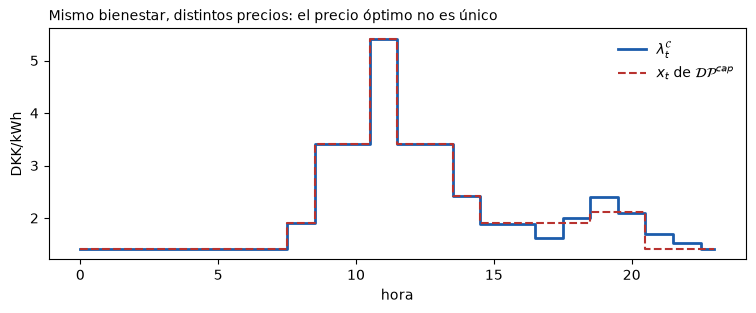

In [5]:
r_cap = dp.solve()
print(f"J^DP,cap = {r_cap.objective:.4f}  J^C = {C.cost['total']:.4f}  ({r_cap.status}, {r_cap.runtime:.1f} s)")
print("residuos:", {k: f"{v:.1e}" for k, v in r_cap.checks.items()})
print("max |J_i(MILP) - J_i(LP propio)| =", f"{max(abs(v) for v in dp.verify_best_responses(r_cap).values()):.1e}")
print(f"Presupuesto con estos precios B = {r_cap.surplus:.2f} DKK  (con lambda^C: {C.surplus:.2f}) -> mismos despachos, precios distintos")
fig, ax = plt.subplots(figsize=(9, 3))
ax.step(hours, C.price, where="mid", lw=2, color="#1c5cab", label=r"$\lambda^{\mathcal{C}}_t$")
ax.step(hours, r_cap.prices["all"], where="mid", lw=1.5, color="#b8322f", ls="--", label=r"$x_t$ de $\mathcal{DP}^{cap}$")
ax.set_xlabel("hora"); ax.set_ylabel("DKK/kWh"); ax.legend(frameon=False)
ax.set_title("Mismo bienestar, distintos precios: el precio óptimo no es único", loc="left", fontsize=10); plt.show()

**Por qué no son únicos**: el objetivo del manager no "ve" los precios, sólo el despacho que inducen. Cualquier $x$ que deje el despacho de $\mathcal C$ dentro de las respuestas óptimas de todos es igual de bueno, y cada uno reparte el bienestar de forma distinta (el presupuesto $B$ cambia). Esa libertad es la que BB e IR intentan aprovechar. Si hiciera falta un precio concreto, se puede añadir una regularización (Table 11e: *price bound and regularization*).

## 8. Paso 2: budget balance $\mathcal{DP}^{BB}$

$$\sum_i\Pi_i=D,\qquad \Pi_i=\Phi_i(\xi_i)-K_i\ \text{(dualidad fuerte)}.$$

- **Igualdad, no desigualdad**: el manager es una entidad sin ánimo de lucro y el excedente es de los miembros. Además, como el objetivo no ve las transferencias, con "$\ge$" el excedente quedaría indeterminado.
- **Diagnóstico rápido con un LP**: si fijamos el despacho de $\mathcal C$, el patrón de complementariedad queda determinado y buscar precios que lo sostengan es un **LP** (`fix_dispatch=C`). Si es factible, la variante alcanza $J^{\mathcal C}$ y es óptima.

In [6]:
for name, kw in [("uniforme", {}), ("por clase de activo", dict(price_groups="asset")), ("por miembro", dict(price_groups="member"))]:
    r = PricingModel(com, "bb", fix_dispatch=C, **kw).solve()
    print(f"BB con el despacho de C fijo, precio {name:20s}: {r.status}")

BB con el despacho de C fijo, precio uniforme            : infeasible


BB con el despacho de C fijo, precio por clase de activo : optimal


BB con el despacho de C fijo, precio por miembro         : optimal


Con precio uniforme, **el despacho exacto de $\mathcal C$ no se puede sostener con budget balance**. Para devolver la renta habría que bajar precios en horas con el cap activo (y los miembros flexibles consumirían más allí) o subirlos en horas de exportación (y las baterías cambiarían). El MILP completo busca entonces el despacho *más cercano* en bienestar:

BB: time limit, gap 5.9e-05, 120 s
pérdida de bienestar vs C = 0.022 DKK;  B = 6.9e-12 DKK


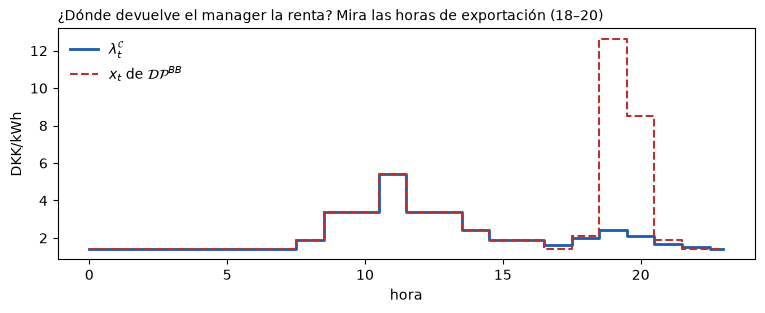

,tipo,C (dual),DP^BB
C1,L1,-13.56,-13.54
C1_PV,L1+PV,2.13,9.90
C1_B,L1+BAT,-9.33,3.37
C1_PVB,L1+PV+BAT,6.49,26.94
C2,L2,-16.18,-16.16
C2_PV,L2+PV,-0.52,7.25
C2_B,L2+BAT,-12.06,0.63
C2_PVB,L2+PV+BAT,3.62,24.06
C3,L3,-21.16,-21.15
C3_PV,L3+PV,-5.52,2.25


In [7]:
r_bb = PricingModel(com, "bb", time_limit=120).solve()
print(f"{r_bb.variant}: {r_bb.status}, gap {r_bb.gap:.1e}, {r_bb.runtime:.0f} s")
print(f"pérdida de bienestar vs C = {r_bb.cost['total'] - C.cost['total']:.3f} DKK;  B = {r_bb.surplus:.1e} DKK")
fig, ax = plt.subplots(figsize=(9, 3))
ax.step(hours, C.price, where="mid", lw=2, color="#1c5cab", label=r"$\lambda^{\mathcal{C}}_t$")
ax.step(hours, r_bb.prices["all"], where="mid", lw=1.5, color="#b8322f", ls="--", label=r"$x_t$ de $\mathcal{DP}^{BB}$")
ax.set_xlabel("hora"); ax.set_ylabel("DKK/kWh"); ax.legend(frameon=False)
ax.set_title("¿Dónde devuelve el manager la renta? Mira las horas de exportación (18–20)", loc="left", fontsize=10); plt.show()
gain = pd.DataFrame({"tipo": {m.consumer_id: m.archetype for m in com.members},
                     "C (dual)": {c: R.member_cost[c] - C.member_cost[c] for c in C.member_cost},
                     "DP^BB": {c: R.member_cost[c] - r_bb.member_cost[c] for c in r_bb.member_cost}}).round(2)
gain

**Interpretación.** El manager devuelve la renta pagando precios muy altos a quien *exporta* en las horas en que nadie puede reaccionar más: las baterías ya descargan al máximo y las cargas ya están en su límite. Casi no cuesta bienestar, pero **la renta va a los dueños de batería/PV**, no a quien la pagó (los miembros rígidos sin activos, que pagan $\lambda_t$ alto en las horas con el cap activo). El reparto bajo BB es **arbitrario**: es uno de muchos óptimos. Por eso hace falta IR.

## 9. Paso 3: individual rationality $\mathcal{DP}^{BB,IR}$

$$J^{\mathcal{DP}}_i=\Phi_i(\xi_i)\le J^{bench}_i\quad\forall i,\qquad J^{bench}_i=J^{\mathcal R}_i\ \text{(base)}\ \text{o}\ \min(J^{\mathcal R}_i,J^{\mathcal I}_i).$$

- Los componentes son los mismos que en Q1 (A5): pagos + desutilidad + coste PV, con la misma regla de fin de día de la batería en todos los modelos.
- **Si es infactible** (uniforme): versión *soft*, $\Phi_i\le J^{bench}_i+s_i$, penalizando $\rho\sum_is_i$ con $\rho=10^3$. Los miembros con $s_i>0$ son los **bloqueantes**, y $\sum_is_i$ es lo que habría que darles.
- **Discriminación de precios**: un vector de precios por clase de activo o por miembro. ¿Cuántas señales hacen falta?

Diagnóstico con el despacho de $\mathcal C$ fijo (LP, instantáneo):

In [8]:
rows = {}
for name, kw in [("asset, soft", dict(price_groups="asset", ir_soft=True)),
                 ("member", dict(price_groups="member"))]:
    r = PricingModel(com, "bb_ir", fix_dispatch=C, **kw).solve()
    rows[name] = {"estado": r.status,
                  "violación IR total [DKK]": round(sum(r.ir_slack.values()), 3) if r.ir_slack else 0.0,
                  "bloqueantes": " ".join(c for c, s in r.ir_slack.items() if s > 1e-4)}
pd.DataFrame(rows).T

,estado,violación IR total [DKK],bloqueantes
"asset, soft",optimal,3.123,C3_PVB C4_PV C4_PVB
member,optimal,0.0,


**Lectura.** Con 4 vectores de precio (uno por clase de activo), el despacho de $\mathcal C$ con BB deja a algunos miembros rígidos sin PV (L3/L4) por debajo de su $\mathcal R$. Son ellos los que bloquean. Con un precio por miembro todo es factible a coste cero.

**Con precio uniforme (MILP completo, 900 s)**: la versión dura no encuentra ningún punto factible (sin probar infactibilidad). La versión *soft* encuentra como mejor punto una violación total de IR de **10.3 DKK**. Los bloqueantes son siempre **C2, C3, C4, C3_B, C4_B**, cargas rígidas o intermedias sin PV. Ese punto cuesta además 10.6 DKK de bienestar frente a $\mathcal C$ y 1.4 kWh por encima del cap.

**Mecanismo** (hipótesis a testear en la Round 2): los miembros rígidos consumen su perfil de referencia justo en las horas con el cap activo. Allí el precio tiene que seguir alto para que los flexibles no entren. Devolver la renta bajando esos precios atrae a los flexibles y rompe el cap. Subirlos en otras horas favorece a quien vende (PV, baterías). Con un único precio por hora no se puede separar *steering* de *reparto*. Reprodúcelo con `python main.py --q2 steps` (tarda: varios MILPs de hasta 600 s).

## 10. Indiferencia: ¿qué arriesga un manager optimista?

El MPEC elige, dentro del conjunto de respuestas óptimas de cada miembro, la que más le conviene al manager. Es la solución **optimista** ([Lecture notes semana 7 – Complementarity modelling](../../Lecture%20Notes/%5BLecture%20Notes%5D%20Complementarity%20Modelling%20for%20Multi-Agent%20Decisions.html), §4 y §10: *"degenerate lower-level solutions are where bilevel optima like to sit"*). Para medir la exposición calculamos, para cada miembro y hora, el rango de $q_{i,t}$ dentro de sus respuestas óptimas a $x=\lambda^{\mathcal C}$. La importación sería máxima si todos rompieran el empate en contra del manager.

horas-miembro indiferentes: 220 de 384


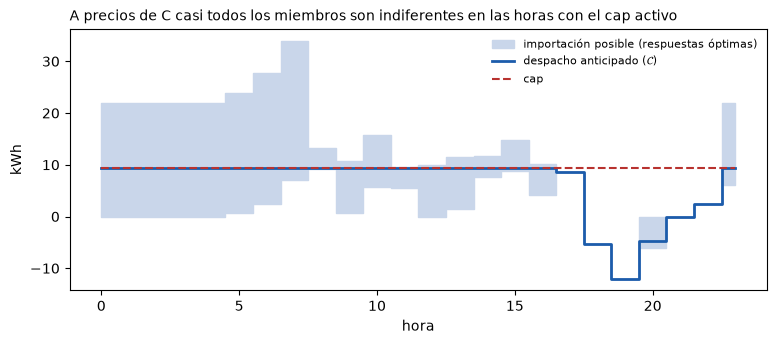

In [9]:
lo, hi, ranges = pessimistic_import(com, C.price)
n_ind = sum(int((r[1] - r[0] > 1e-5).sum()) for r in ranges.values())
print(f"horas-miembro indiferentes: {n_ind} de {16*24}")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.fill_between(hours, lo, hi, step="mid", color="#c9d6ea", label="importación posible (respuestas óptimas)")
ax.step(hours, sum(s["q"] for s in C.schedule.values()), where="mid", color="#1c5cab", lw=2, label="despacho anticipado ($\\mathcal{C}$)")
ax.step(hours, C.cap, where="mid", color="#b8322f", ls="--", label="cap")
ax.set_xlabel("hora"); ax.set_ylabel("kWh"); ax.legend(frameon=False, fontsize=8)
ax.set_title("A precios de C casi todos los miembros son indiferentes en las horas con el cap activo", loc="left", fontsize=10); plt.show()

**Lectura.** El despacho anticipado se queda en el cap, pero a los mismos precios los miembros podrían, sin perder nada ellos, importar mucho más. Es un límite hora a hora: cada miembro no puede subir en todas las horas a la vez porque su $E^{\min}$ acopla las horas. El manager depende de que los empates se rompan a su favor.
- **En la práctica**: precios $\varepsilon$ dentro del empate (como el 34.9 en vez de 35 de las notas), que hacen la respuesta única a cambio de un poco de bienestar o presupuesto; o una evaluación pesimista.
- **Enlace con Q3**: si además las preferencias son inciertas, los miembros pueden caer del lado "malo" del empate. Ahí la penalización $\alpha$ convierte la indiferencia en coste esperado.

## 11. Qué falta para la Round 2 (viernes 20/11)

1. **Estudio en tres pasos** (obligatorio): cap → +BB → +IR, con métricas respecto a $\mathcal C$ (pérdida de bienestar, flexibilidad, cap), a $\mathcal R$ y a $\mathcal I$ (ganancia por miembro, nº de miembros peor que $\mathcal R$/$\mathcal I$, violación IR total, bloqueantes). → `python main.py --q2 steps`.
2. **Sensibilidad a los términos del contrato** (Table 11c): por ejemplo $\beta^{DSO}$ y $f$ (tightness del cap). Hipótesis a escribir *antes* de correrla: con el cap más holgado, la renta $\sum\gamma_t\overline P_t$ baja, BB es más fácil y menos miembros bloquean. Con el cap más apretado, los rígidos sin PV pagan más y IR se vuelve infactible antes.
3. **Experiment cards** con hipótesis testables (ver la plantilla del enunciado).

### Glosario rápido
| Inglés | Español |
|---|---|
| best response | respuesta óptima |
| inducible region | región inducible |
| budget balance | equilibrio presupuestario |
| individual rationality | racionalidad individual (nadie pierde participando) |
| congestion rent | renta de congestión |
| optimistic / pessimistic bilevel | bilevel optimista / pesimista |
| blocking member | miembro bloqueante |